# Etapa E — Avaliação final no conjunto de teste

**Uso único do teste.** Tudo o que define o modelo foi decidido antes, só com
treino e validação (Etapas C e D, DIARIO de 29/09). Nada aqui volta a mudar o
modelo.

Protocolo fixado antes de rodar:
- **MLP final (Etapa D):** 5 atributos normalizados → 8 neurônios Tanh → 8
  saídas; init padrão; entropia cruzada categórica com peso por classe
  n/(N_L·n_c); Adam lr 0,01; mini-batch 64; até 1000 épocas, pesos da época de
  menor perda de validação. Treino só no conjunto de treino. Sementes 0, 1, 2.
- **Referência linear:** regressão softmax com a mesma função custo com peso,
  SGD lr 0,1, 2000 épocas, sementes 0, 1, 2 (única diferença: sem camada oculta).
- **Régua da chave de identificação:** centro de FME mais próximo (sem treino).
- **Métricas:** acurácia balanceada (principal), F1 macro, acurácia,
  sensibilidade e precisão por espécie, matriz de confusão (linha = previsto,
  coluna = verdadeiro, como no Slides_6). Validação ao lado, para comparar.

In [1]:
import copy
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

dados = np.load("../dados_processados/etapa2.npz", allow_pickle=True)
X = dados["X_simples"].astype(np.float32)  # normalizado com média/desvio do treino (Etapa 2)
y_especie = dados["y_simples"]
ordem_especies = pd.Series(y_especie).value_counts().index.tolist()
y = np.array([ordem_especies.index(e) for e in y_especie])
N = len(ordem_especies)

pt, pv, pte = dados["pos_treino_simples"], dados["pos_val_simples"], dados["pos_teste_simples"]
Xtr, ytr, Xva, yva, Xte, yte = X[pt], y[pt], X[pv], y[pv], X[pte], y[pte]
pesos = len(ytr) / (N * np.bincount(ytr, minlength=N))
print(f"Treino {len(ytr)}  Validação {len(yva)}  Teste {len(yte)}")
print("Gravações por espécie no teste:", dict(zip(ordem_especies, np.bincount(yte, minlength=N))))

Treino 9386  Validação 2011  Teste 2011
Gravações por espécie no teste: {'Myotis_lavali': np.int64(1092), 'Molossus_molossus': np.int64(247), 'Lasiurus_blossevillii': np.int64(163), 'Neoeptesicus_furinalis': np.int64(152), 'Eumops_sp': np.int64(109), 'Molossus_currentium': np.int64(108), 'Molossops_temminckii': np.int64(83), 'Myotis_nigricans': np.int64(57)}


In [2]:
def treina(modelo, otimizador, n_epocas, semente):
    torch.manual_seed(semente)
    criterio = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32))
    loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=64, shuffle=True)
    tXva, tyva = torch.from_numpy(Xva), torch.from_numpy(yva)
    melhor, melhores, melhor_ep = float("inf"), None, -1
    for ep in range(n_epocas):
        modelo.train()
        for xb, yb in loader:
            otimizador.zero_grad()
            criterio(modelo(xb), yb).backward()
            otimizador.step()
        modelo.eval()
        with torch.no_grad():
            perda_val = criterio(modelo(tXva), tyva).item()
        if perda_val < melhor:
            melhor, melhores, melhor_ep = perda_val, copy.deepcopy(modelo.state_dict()), ep + 1
    modelo.load_state_dict(melhores)
    return melhor_ep


def prever(modelo, Xp):
    modelo.eval()
    with torch.no_grad():
        return torch.softmax(modelo(torch.from_numpy(Xp)), dim=1).numpy().argmax(axis=1)


def matriz_confusao(y_real, y_prev):
    m = np.zeros((N, N), dtype=int)
    for p, r in zip(y_prev, y_real):
        m[p, r] += 1  # linha = previsto, coluna = verdadeiro
    return m


def metricas(m):
    vp = np.diag(m).astype(float)
    sens = vp / m.sum(axis=0)
    tot_prev = m.sum(axis=1)
    prec = np.divide(vp, tot_prev, out=np.zeros_like(vp), where=tot_prev > 0)
    f1 = np.divide(2 * prec * sens, prec + sens, out=np.zeros_like(vp), where=(prec + sens) > 0)
    return {"acurácia balanceada": sens.mean(), "F1 macro": f1.mean(), "acurácia": vp.sum() / m.sum(),
            "sens": sens, "prec": prec}

## Treino e avaliação (MLP final e referência linear)

In [3]:
resultados = {"MLP": [], "linear": []}
matrizes_teste = {"MLP": [], "linear": []}
for s in [0, 1, 2]:
    torch.manual_seed(s)
    mlp = nn.Sequential(nn.Linear(5, 8), nn.Tanh(), nn.Linear(8, N))
    ep = treina(mlp, torch.optim.Adam(mlp.parameters(), lr=0.01), 1000, s)

    torch.manual_seed(s)
    lin = nn.Sequential(nn.Linear(5, N))
    ep_lin = treina(lin, torch.optim.SGD(lin.parameters(), lr=0.1), 2000, s)

    for nome, modelo, e in [("MLP", mlp, ep), ("linear", lin, ep_lin)]:
        m_va = matriz_confusao(yva, prever(modelo, Xva))
        m_te = matriz_confusao(yte, prever(modelo, Xte))
        matrizes_teste[nome].append(m_te)
        resultados[nome].append({"semente": s, "melhor época": e, "val": metricas(m_va), "teste": metricas(m_te)})
    print(f"semente {s} pronta (melhor época MLP {ep}, linear {ep_lin})")

# régua da chave (sem treino): centro de FME mais próximo
CENTROS = {"Eumops_sp": 18.0, "Molossus_currentium": 30.0, "Molossus_molossus": 34.0,
           "Neoeptesicus_furinalis": 39.0, "Lasiurus_blossevillii": 46.0,
           "Molossops_temminckii": 50.0, "Myotis_lavali": 50.5, "Myotis_nigricans": 53.5}
centros = np.array([CENTROS[e] for e in ordem_especies])
fme = lambda Xp: Xp[:, 3] * dados["desvio_simples"][3] + dados["media_simples"][3]
regua = {conj: metricas(matriz_confusao(yy, np.argmin(np.abs(fme(XX)[:, None] - centros[None, :]), axis=1)))
         for conj, XX, yy in [("val", Xva, yva), ("teste", Xte, yte)]}

semente 0 pronta (melhor época MLP 818, linear 999)


semente 1 pronta (melhor época MLP 339, linear 1040)


semente 2 pronta (melhor época MLP 438, linear 1803)


## Resultado principal

In [4]:
linhas = []
for nome in ["MLP", "linear"]:
    for conj in ["val", "teste"]:
        for k in ["acurácia balanceada", "F1 macro", "acurácia"]:
            v = np.array([r[conj][k] for r in resultados[nome]])
            linhas.append({"modelo": nome, "conjunto": conj, "métrica": k, "média": v.mean(), "desvio": v.std()})
for conj in ["val", "teste"]:
    for k in ["acurácia balanceada", "F1 macro", "acurácia"]:
        linhas.append({"modelo": "régua da chave", "conjunto": conj, "métrica": k, "média": regua[conj][k], "desvio": 0.0})
tabela = pd.DataFrame(linhas).pivot_table(index=["modelo", "métrica"], columns="conjunto", values=["média", "desvio"])
tabela.round(3)

desvio         média       
conjunto                            teste    val  teste    val
modelo         métrica                                        
MLP            F1 macro             0.005  0.004  0.926  0.922
               acurácia             0.004  0.003  0.955  0.950
               acurácia balanceada  0.000  0.002  0.959  0.966
linear         F1 macro             0.002  0.002  0.894  0.891
               acurácia             0.001  0.001  0.932  0.927
               acurácia balanceada  0.001  0.002  0.938  0.947
régua da chave F1 macro             0.000  0.000  0.623  0.612
               acurácia             0.000  0.000  0.553  0.545
               acurácia balanceada  0.000  0.000  0.697  0.694

## Por espécie no teste (média das 3 sementes)

In [5]:
por_especie = pd.DataFrame({
    "n no teste": np.bincount(yte, minlength=N),
    "sensibilidade MLP": np.mean([r["teste"]["sens"] for r in resultados["MLP"]], axis=0),
    "precisão MLP": np.mean([r["teste"]["prec"] for r in resultados["MLP"]], axis=0),
    "sensibilidade linear": np.mean([r["teste"]["sens"] for r in resultados["linear"]], axis=0),
    "precisão linear": np.mean([r["teste"]["prec"] for r in resultados["linear"]], axis=0),
}, index=ordem_especies)
por_especie.round(3)

,n no teste,sensibilidade MLP,precisão MLP,sensibilidade linear,precisão linear
Myotis_lavali,1092,0.956,0.996,0.948,0.991
Molossus_molossus,247,0.928,0.979,0.823,0.971
Lasiurus_blossevillii,163,0.957,0.921,0.877,0.923
Neoeptesicus_furinalis,152,0.936,0.936,0.936,0.893
Eumops_sp,109,0.985,0.964,0.976,0.973
Molossus_currentium,108,0.963,0.897,0.981,0.716
Molossops_temminckii,83,0.996,0.914,1.000,0.922
Myotis_nigricans,57,0.953,0.613,0.965,0.573


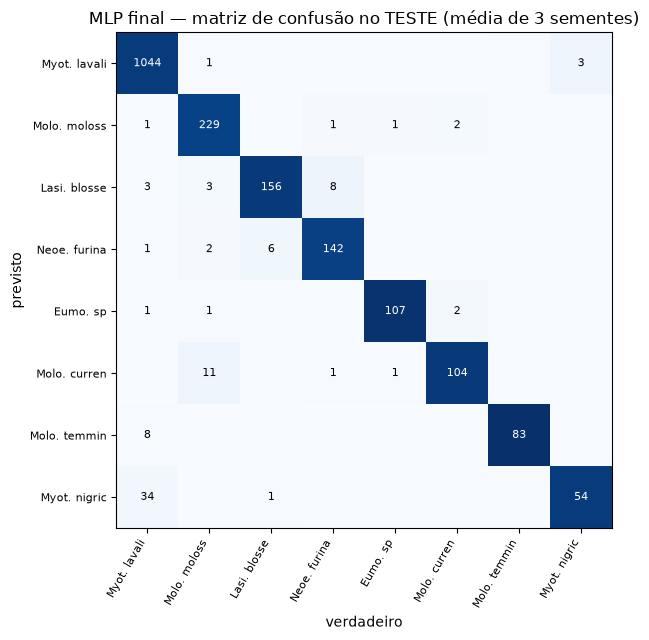

Maiores confusões no teste (verdadeiro → previsto, média de 3 sementes):
  Myotis_lavali            → Myotis_nigricans         33.7
  Molossus_molossus        → Molossus_currentium      10.7
  Myotis_lavali            → Molossops_temminckii     8.0
  Neoeptesicus_furinalis   → Lasiurus_blossevillii    7.7
  Lasiurus_blossevillii    → Neoeptesicus_furinalis   6.0
  Molossus_molossus        → Lasiurus_blossevillii    3.0
  Myotis_nigricans         → Myotis_lavali            2.7
  Myotis_lavali            → Lasiurus_blossevillii    2.7
Total de erros: 90.7 de 2011


In [6]:
m = np.mean(matrizes_teste["MLP"], axis=0)
frac = m / m.sum(axis=0, keepdims=True)
curtos = [e.split("_")[0][:4] + ". " + e.split("_")[1][:6] for e in ordem_especies]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
for i in range(N):
    for j in range(N):
        if m[i, j] >= 0.5:
            ax.text(j, i, f"{m[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if frac[i, j] > 0.5 else "black")
ax.set_xticks(range(N), curtos, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(N), curtos, fontsize=8)
ax.set_xlabel("verdadeiro")
ax.set_ylabel("previsto")
ax.set_title("MLP final — matriz de confusão no TESTE (média de 3 sementes)")
fig.tight_layout()
plt.show()

erros = [(m[i, j], ordem_especies[j], ordem_especies[i]) for i in range(N) for j in range(N) if i != j and m[i, j] >= 1]
print("Maiores confusões no teste (verdadeiro → previsto, média de 3 sementes):")
for v, real, prev in sorted(erros, reverse=True)[:8]:
    print(f"  {real:24s} → {prev:24s} {v:.1f}")
print(f"Total de erros: {m.sum() - np.trace(m):.1f} de {int(m.sum())}")

In [7]:
# guarda os números da Etapa E (fora do git) para o artigo e o notebook final
json.dump({nome: [{"semente": r["semente"], "melhor época": r["melhor época"],
                   **{f"{conj} {k}": float(r[conj][k]) for conj in ["val", "teste"]
                      for k in ["acurácia balanceada", "F1 macro", "acurácia"]}}
                  for r in resultados[nome]] for nome in resultados},
          open("../dados_processados/etapa_e_resultados.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)